# 01 · Liquidity profile

Data quality first, then liquidity metrics for the universe. Every number below comes from `src/` functions on the cached yfinance bars (`data/cache/`). Run `python -m src.pipeline` first.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
from src.config import UNIVERSE, FX_TICKER, RESULTS_DIR
from src.reporting import charts
R = lambda name: pd.read_csv(RESULTS_DIR / name)
import plotly.io as pio
pio.renderers.default = "png"  # static images so the notebooks render on GitHub
pio.renderers["png"].width, pio.renderers["png"].height = 900, 480

## Data quality: what do 1-minute yfinance bars actually contain?

* BMV moved its session from 07:30–14:00 to 08:30–15:00 (CDMX) when the US left daylight time on 2 Nov; yfinance stops at 13:59 in both regimes, so **the last BMV hour and the closing auction are missing after the switch**.
* `coverage_all` = Σ 1-min volume / official daily volume; `coverage_exec` removes the opening-auction bar and prints > 25× the day's median minute (block crosses at BMV, bad prints for AAPL).

In [2]:
dq = R('data_quality.csv')
dq.groupby(['ticker', 'session_open']).agg(days=('date', 'count'), first_bar=('first_bar', 'first'), last_bar=('last_bar', 'max'),
    median_bars=('bars', 'median'), coverage_all=('coverage_all', 'median'), coverage_exec=('coverage_exec', 'median')).round(2)

days first_bar last_bar  median_bars  coverage_all  coverage_exec
ticker          session_open                                                                   
AAPL            09:30           20     09:30    15:59        390.0          1.95           0.63
AMXB.MX         07:30           10     07:30    13:59        389.0          0.68           0.60
                08:30            9     08:30    13:59        330.0          0.53           0.37
GFNORTEO.MX     07:30           10     07:30    13:59        389.0          0.87           0.63
                08:30            9     08:30    13:59        330.0          0.52           0.48
GMEXICOB.MX     07:30           10     07:30    13:59        390.0          0.97           0.49
                08:30            9     08:30    13:59        330.0          0.86           0.38
IVV             09:30           20     09:30    15:59        390.0          0.63           0.50
NAFTRACISHRS.MX 07:30           10     07:30    13:59         98.0          0.93           0.27
                08:30            9     08:30    13:59         80.0          0.66           0.36
WALMEX.MX       07:30           10     07:30    13:59        386.5          0.70           0.57
                08:30            9     08:30    13:59        330.0          0.54           0.48

## Liquidity summary

Formulas are in the docstrings of `src/liquidity/metrics.py` and `src/liquidity/spread_estimators.py`.

In [3]:
liq = R('liquidity_summary.csv')
liq[['ticker','market','price_local','adv_usd_m','daily_vol_bps','cs_spread_bps','roll_spread_bps','model_spread_bps',
     'usd_per_bp_1m','amihud_bps_per_usd_m','pct_minutes_traded']].round(3)

,ticker,market,price_local,adv_usd_m,daily_vol_bps,cs_spread_bps,roll_spread_bps,model_spread_bps,usd_per_bp_1m,amihud_bps_per_usd_m,pct_minutes_traded
0,WALMEX.MX,MX,54.67,42.507,137.478,2.264,4.579,2.369,10280.975,3.990,0.994
1,GMEXICOB.MX,MX,219.64,94.334,204.345,2.380,7.196,2.206,17151.467,1.499,0.997
2,AMXB.MX,MX,23.55,45.160,158.842,3.127,4.966,4.346,10694.051,3.128,0.990
3,GFNORTEO.MX,MX,205.44,90.265,134.666,1.703,5.607,1.410,25037.615,1.283,0.997
4,NAFTRACISHRS.MX,MX,71.11,16.695,78.180,0.045,7.928,8.125,5029.536,3.937,0.232
5,IVV,US,757.65,4235.594,94.279,0.817,0.000,0.948,2282586.706,0.021,1.000
6,AAPL,US,356.27,16314.257,138.699,1.940,1.358,2.676,6458260.022,0.008,1.000


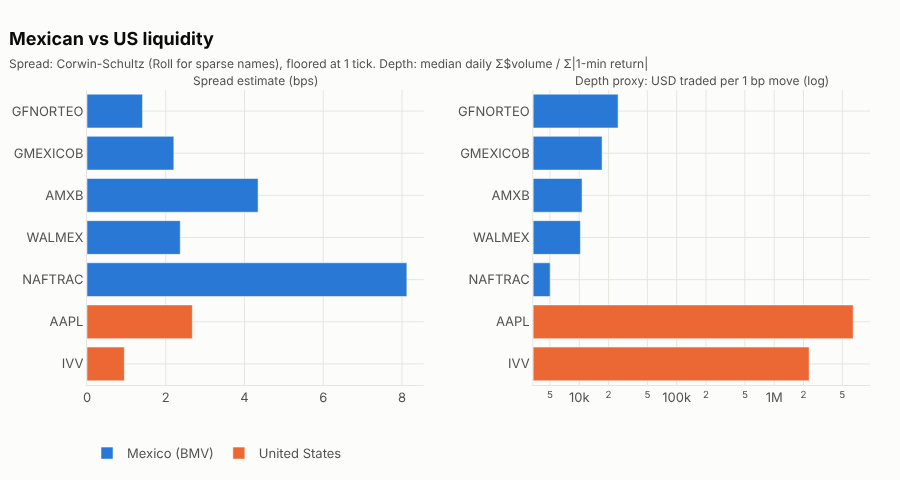

In [4]:
charts.liquidity_bars(liq).show()

**Reading it.** MX large caps trade in essentially every minute, but each basis point of price movement absorbs two to three orders of magnitude fewer dollars than in IVV/AAPL. NAFTRAC — the main MX equity ETF — trades in only ~a quarter of minutes on the lit book: its liquidity sits in creations/redemptions and block crosses, so Corwin-Schultz collapses toward zero there and the model uses Roll instead.

## Recomputing one metric from scratch

Spread estimates for one ticker and day, straight from the functions:

In [5]:
from src.data.loaders import load_enriched
from src.liquidity.spread_estimators import corwin_schultz_bps, roll_bps
b = load_enriched('WALMEX.MX')
pd.DataFrame({'cs_bps': corwin_schultz_bps(b, by='date'), 'roll_bps': roll_bps(b, by='date')}).round(2).tail(10)

,cs_bps,roll_bps
date,,
2026-10-30,1.78,5.56
2026-11-03,2.75,0.00
2026-11-04,3.70,6.70
2026-11-05,4.07,7.94
2026-11-06,2.47,8.72
2026-11-09,2.26,5.26
2026-11-10,2.72,3.85
2026-11-11,1.48,4.13
2026-11-12,2.51,2.11
